Terrain classifier defined with 6 terrain types.
Uses HSV ranges — robust to shadows (V channel separates brightness from color).
KMeans fitted with K=7 clusters

Cluster Centers (HSV):
  Cluster 0: H=81.5, S=88.9, V=56.3
  Cluster 1: H=31.1, S=35.1, V=115.1
  Cluster 2: H=69.3, S=37.0, V=67.9
  Cluster 3: H=33.3, S=44.7, V=192.1
  Cluster 4: H=85.1, S=116.4, V=50.5
  Cluster 5: H=78.4, S=63.1, V=60.4
  Cluster 6: H=35.2, S=29.9, V=76.5
Terrain Assignment:
  Cluster 0 (H=81, S=89, V=56) → forest | cost=80
  Cluster 1 (H=31, S=35, V=115) → rocky | cost=40
  Cluster 2 (H=69, S=37, V=68) → rocky | cost=40
  Cluster 3 (H=33, S=45, V=192) → open_land | cost=10
  Cluster 4 (H=85, S=116, V=50) → open_land | cost=10
  Cluster 5 (H=78, S=63, V=60) → vegetation | cost=50
  Cluster 6 (H=35, S=30, V=76) → rocky | cost=40

Water pixels: 0.0% of image


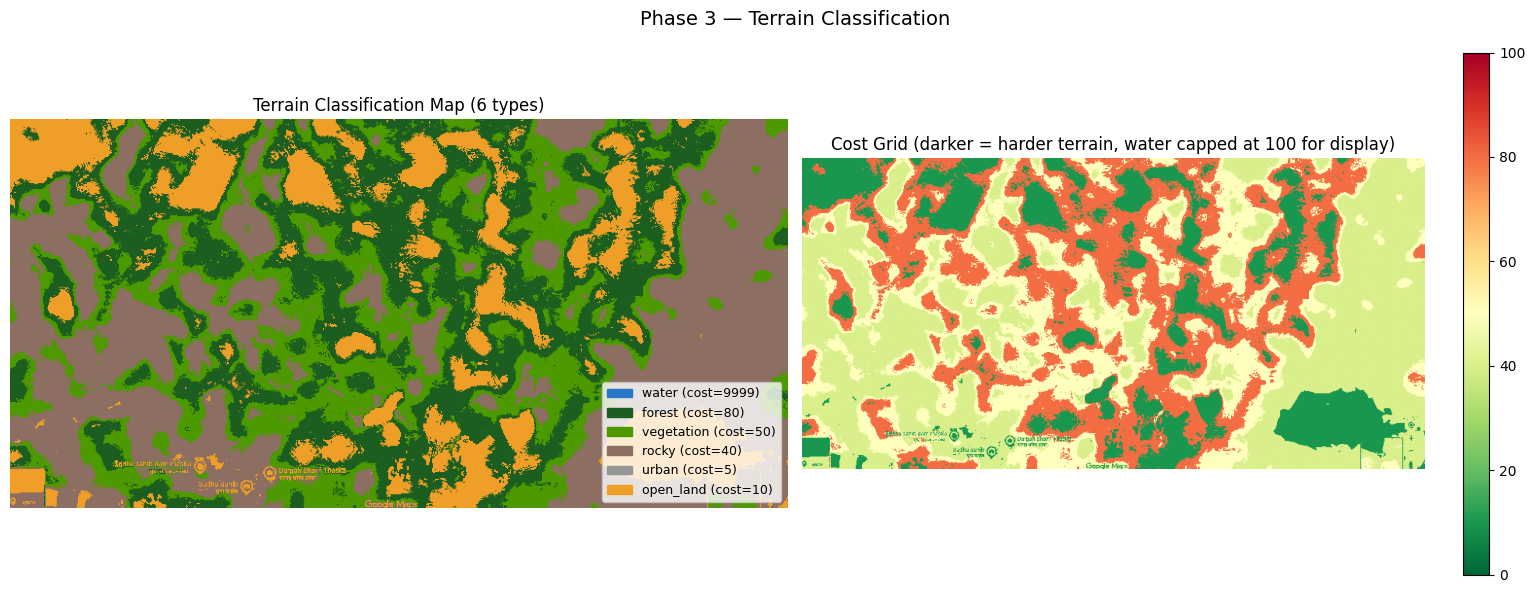

cost_grid.npy and terrain_map.npy saved!


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.cluster import KMeans

# ── LOAD PREPROCESSED IMAGE ─────────────────────────────
image_hsv = np.load(r"F:\resume project\path project\input\preprocessed.npy")

# ── TERRAIN DEFINITIONS (6 types) ───────────────────────
# Each terrain has: traversal cost + display color
TERRAIN = {
    "water":      {"cost": 9999, "color": [41,  120, 200]},  # impassable
    "forest":     {"cost": 80,   "color": [27,  94,  32]},   # hard
    "vegetation": {"cost": 50,   "color": [76,  153, 0]},    # medium
    "rocky":      {"cost": 40,   "color": [141, 110, 99]},   # medium
    "urban":      {"cost": 5,    "color": [150, 150, 150]},  # easy
    "open_land":  {"cost": 10,   "color": [239, 159, 39]},   # easy
}
# ── HSV-BASED TERRAIN CLASSIFIER ────────────────────────
# OpenCV HSV ranges: H=0-179, S=0-255, V=0-255

def get_terrain_hsv(h, s, v):
    """
    Classifies a pixel's terrain type from its HSV values.
    H (Hue)        : color type  — 0-179 in OpenCV
    S (Saturation) : color intensity
    V (Value)      : brightness
    """
    # Water: very dark pixels OR blue/cyan hue
    if v < 50:
        return "water"
    if 90 <= h <= 130 and s > 60:
        return "water"

    # Forest: dark green (high saturation, low brightness)
    if 35 <= h <= 85 and s > 80 and v < 140:
        return "forest"

    # Vegetation: lighter green
    if 35 <= h <= 85 and s > 40:
        return "vegetation"

    # Urban: grey/white (low saturation, high brightness)
    if s < 40 and v >= 150:
        return "urban"

    # Rocky: low saturation, mid brightness
    if s < 80 and 60 <= v < 150:
        return "rocky"

    # Default
    return "open_land"

print("Terrain classifier defined with 6 terrain types.")
print("Uses HSV ranges — robust to shadows (V channel separates brightness from color).")
# ── STEP 1: RESHAPE FOR K-MEANS ─────────────────────────
h, w, c = image_hsv.shape
pixels = image_hsv.reshape(-1, 3).astype(np.float32)
# reshape(-1, 3): converts (H, W, 3) image → (H*W, 3) pixel list
# Each row = one pixel with [H, S, V] values

# ── STEP 2: K-MEANS CLUSTERING ──────────────────────────
K = 7  # number of terrain clusters (tunable)
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
kmeans.fit(pixels)
labels     = kmeans.labels_.reshape(h, w)
centers    = kmeans.cluster_centers_

print(f"KMeans fitted with K={K} clusters")
print("\nCluster Centers (HSV):")
for i, center in enumerate(centers):
    print(f"  Cluster {i}: H={center[0]:.1f}, S={center[1]:.1f}, V={center[2]:.1f}")
# ── STEP 3: CLASSIFY EACH CLUSTER → TERRAIN ─────────────
# Each cluster center is passed to get_terrain_hsv()
# All pixels in that cluster get the terrain's cost + color

cost_grid = np.zeros((h, w), dtype=np.float32)
color_map = np.zeros((h, w, 3), dtype=np.uint8)

print("Terrain Assignment:")
for i, center in enumerate(centers):
    ch, cs, cv  = float(center[0]), float(center[1]), float(center[2])
    name        = get_terrain_hsv(ch, cs, cv)
    mask        = labels == i
    cost_grid[mask] = TERRAIN[name]["cost"]
    color_map[mask] = TERRAIN[name]["color"]
    print(f"  Cluster {i} (H={ch:.0f}, S={cs:.0f}, V={cv:.0f}) → {name} | cost={TERRAIN[name]['cost']}")

water_pct = (cost_grid >= 9999).sum() / cost_grid.size * 100
print(f"\nWater pixels: {water_pct:.1f}% of image")
# ── STEP 4: VISUALIZE ───────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Terrain color map
axes[0].imshow(color_map)
axes[0].set_title("Terrain Classification Map (6 types)")
axes[0].axis('off')

# Legend
patches = [mpatches.Patch(color=np.array(v["color"])/255,
           label=f"{k} (cost={v['cost']})")
           for k, v in TERRAIN.items()]
axes[0].legend(handles=patches, loc='lower right', fontsize=9)

# Cost grid (cap water at 100 so colors are visible)
display_grid = np.clip(cost_grid, 0, 100)
im = axes[1].imshow(display_grid, cmap='RdYlGn_r', vmin=0, vmax=100)
axes[1].set_title("Cost Grid (darker = harder terrain, water capped at 100 for display)")
axes[1].axis('off')
plt.colorbar(im, ax=axes[1])

plt.suptitle("Phase 3 — Terrain Classification", fontsize=14)
plt.tight_layout()
plt.show()

# ── SAVE ─────────────────────────────────────────────────
np.save(r"F:\resume project\path project\input\cost_grid.npy", cost_grid)
np.save(r"F:\resume project\path project\input\terrain_map.npy", color_map)
print("cost_grid.npy and terrain_map.npy saved!")
